# Washing-machine exploratory analysis

This notebook uses the existing official cleaned REFIT household CSVs and appliance mappings in `data/documentation/CLEAN_READ_ME_081116.txt`. It reads one household at a time, keeps one-minute aggregate and washing-machine series, and saves tables, plots, and an interpretation report in `outputs/02_washing_machine_eda/`.

Event rule: a minute is active at 20 W or more. Active periods separated by at most 10 valid, below-threshold minutes are joined to avoid splitting one cycle into short phases. Runs shorter than 20 minutes are not counted as operating events; this duration is intended to screen out brief appliance transients, not to assert a precise manufacturer cycle boundary. `Issues == 1` readings are excluded from appliance/event analysis because the dataset documentation flags aggregate/submeter inconsistencies. Times are treated as the dataset's naive local clock for hour/day summaries.

The REFIT dataset paper and NILMTK evaluation paper are cited in the project-root `REFERENCES.md`. They motivate documenting the source cadence, preprocessing, and evaluation context; the event thresholds here are project heuristics and are not borrowed or validated from those studies.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data" / "cleaned").is_dir():
            return candidate
    raise FileNotFoundError("Could not find the project data/cleaned folder from the current directory.")

PROJECT_ROOT = find_project_root()
CLEAN_DIR = PROJECT_ROOT / "data" / "cleaned" / "CLEAN_REFIT_081116"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "02_washing_machine_eda"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Appliance numbers are taken from the supplied REFIT documentation.
WASHING_MACHINE_CHANNELS = {1: 5, 2: 2, 6: 2, 9: 3, 10: 5}
ACTIVE_THRESHOLD_W = 20
MAX_BRIDGED_OFF_MINUTES = 10
MIN_EVENT_DURATION_MINUTES = 20

profiles = {}
quality_rows = []
for house, appliance_number in WASHING_MACHINE_CHANNELS.items():
    filename = f"CLEAN_House{house}.csv"
    path = CLEAN_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"Expected cleaned household file was not found: {path}")

    appliance = f"Appliance{appliance_number}"
    frame = pd.read_csv(
        path,
        usecols=["Time", "Aggregate", appliance, "Issues"],
        dtype={"Aggregate": "float32", appliance: "float32", "Issues": "float32"},
    )
    input_rows = len(frame)
    frame["Time"] = pd.to_datetime(frame["Time"], errors="coerce")
    invalid_timestamps = int(frame["Time"].isna().sum())
    frame = frame.dropna(subset=["Time"])
    duplicate_timestamps = int(frame["Time"].duplicated(keep="last").sum())
    frame = frame.drop_duplicates("Time", keep="last").sort_values("Time", kind="stable")
    intervals = frame["Time"].diff().dt.total_seconds().dropna()

    issue_rows = int(frame["Issues"].eq(1).sum())
    raw_missing = int(frame[appliance].isna().sum())
    zero_samples = int(frame[appliance].eq(0).sum())
    positive_samples = int(frame[appliance].gt(0).sum())
    frame = frame.set_index("Time").sort_index()
    power = frame[["Aggregate", appliance]].copy()
    power.loc[frame["Issues"].eq(1), ["Aggregate", appliance]] = np.nan
    minute = power.resample("1min").mean()
    full_index = pd.date_range(minute.index.min().floor("min"), minute.index.max().floor("min"), freq="1min")
    minute = minute.reindex(full_index)
    minute.index.name = "Time"
    minute = minute.rename(columns={appliance: "WashingMachine"})
    profiles[house] = minute

    valid_minutes = int(minute["WashingMachine"].notna().sum())
    zero_minutes = int(minute["WashingMachine"].eq(0).sum())
    below_threshold_minutes = int(minute["WashingMachine"].lt(ACTIVE_THRESHOLD_W).sum())
    quality_rows.append({
        "house": house,
        "washing_machine_channel": appliance,
        "input_rows": input_rows,
        "invalid_timestamps": invalid_timestamps,
        "duplicate_timestamps_removed": duplicate_timestamps,
        "date_start": str(frame.index.min()),
        "date_end": str(frame.index.max()),
        "interval_median_seconds": float(intervals.median()),
        "interval_p95_seconds": float(intervals.quantile(0.95)),
        "gaps_over_60_seconds": int((intervals > 60).sum()),
        "raw_washing_machine_missing_rows": raw_missing,
        "issues_rows_excluded": issue_rows,
        "issues_percent": 100 * issue_rows / len(frame),
        "valid_washing_machine_minutes": valid_minutes,
        "zero_washing_machine_minutes": zero_minutes,
        "zero_percent_of_valid_minutes": 100 * zero_minutes / valid_minutes if valid_minutes else np.nan,
        "below_20w_percent_of_valid_minutes": 100 * below_threshold_minutes / valid_minutes if valid_minutes else np.nan,
        "positive_raw_samples": positive_samples,
        "max_washing_machine_watts": float(frame[appliance].max()),
    })
    print(f"Loaded House {house}: {len(frame):,} source rows -> {len(minute):,} one-minute bins")
    del frame, power, minute

quality = pd.DataFrame(quality_rows)
print(quality[["house", "washing_machine_channel", "date_start", "date_end", "interval_median_seconds", "zero_percent_of_valid_minutes", "issues_percent"]].to_string(index=False))

Loaded House 1: 6,960,008 source rows -> 920,091 one-minute bins


Loaded House 2: 5,733,526 source rows -> 889,078 one-minute bins


Loaded House 6: 6,241,971 source rows -> 831,480 one-minute bins


Loaded House 9: 6,169,525 source rows -> 818,007 one-minute bins


Loaded House 10: 6,739,284 source rows -> 845,257 one-minute bins
 house washing_machine_channel          date_start            date_end  interval_median_seconds  zero_percent_of_valid_minutes  issues_percent
     1              Appliance5 2013-10-09 13:06:17 2015-07-10 11:56:32                      7.0                      97.632573        0.835962
     2              Appliance2 2013-09-17 22:08:11 2015-05-28 08:05:43                      7.0                      94.397598        0.496100
     6              Appliance2 2013-11-28 12:15:35 2015-06-28 22:14:45                      7.0                      97.451176        0.551925
     9              Appliance3 2013-12-17 17:26:20 2015-07-08 18:52:50                      7.0                      90.650210        0.522342
    10              Appliance5 2013-11-20 11:31:18 2015-06-30 11:07:07                      7.0                      90.241935        0.447555


In [2]:
def detect_events(power, threshold_w=ACTIVE_THRESHOLD_W,
                  max_off_gap=MAX_BRIDGED_OFF_MINUTES,
                  min_duration=MIN_EVENT_DURATION_MINUTES):
    """Detect threshold runs, bridging only short, fully observed off periods."""
    active = power.ge(threshold_w).fillna(False)
    run_id = active.ne(active.shift(fill_value=False)).cumsum()
    for _, run in active.groupby(run_id):
        if run.iloc[0] or len(run) > max_off_gap or run.index[0] == active.index[0] or run.index[-1] == active.index[-1]:
            continue
        if (power.loc[run.index].notna().all()
                and active.loc[run.index[0] - pd.Timedelta(minutes=1)]
                and active.loc[run.index[-1] + pd.Timedelta(minutes=1)]):
            active.loc[run.index] = True

    event_id = active.ne(active.shift(fill_value=False)).cumsum()
    rows = []
    for _, run in active.groupby(event_id):
        if not run.iloc[0]:
            continue
        duration = len(run)
        if duration >= min_duration:
            values = power.loc[run.index]
            rows.append({
                "start": run.index[0],
                "end": run.index[-1],
                "duration_minutes": duration,
                "peak_power_w": float(values.max()),
                "energy_kwh": float(values.sum() / 60_000),
            })
    return pd.DataFrame(rows, columns=["start", "end", "duration_minutes", "peak_power_w", "energy_kwh"])

event_frames = []
hourly_by_house = []
weekday_by_house = []
daily_profiles = {}
for house, minute in profiles.items():
    power = minute["WashingMachine"]
    house_events = detect_events(power)
    if not house_events.empty:
        house_events.insert(0, "house", house)
        house_events["weekday"] = house_events["start"].dt.dayofweek
        event_frames.append(house_events)

    hour_values = pd.DataFrame({
        "hour": minute.index.hour,
        "mean_power_w": power.to_numpy(),
        "active_fraction": power.ge(ACTIVE_THRESHOLD_W).where(power.notna()).to_numpy(),
    }).groupby("hour").mean().reindex(range(24))
    hour_values["house"] = house
    hourly_by_house.append(hour_values.reset_index())

    weekday_values = pd.DataFrame({
        "weekday": minute.index.dayofweek,
        "mean_power_w": power.to_numpy(),
        "active_fraction": power.ge(ACTIVE_THRESHOLD_W).where(power.notna()).to_numpy(),
    }).groupby("weekday").mean().reindex(range(7))
    weekday_values["house"] = house
    weekday_by_house.append(weekday_values.reset_index())

    minute_of_day = minute.index.hour * 60 + minute.index.minute
    daily_profiles[house] = minute[["Aggregate", "WashingMachine"]].groupby(minute_of_day).mean().reindex(range(1440))

events = pd.concat(event_frames, ignore_index=True) if event_frames else pd.DataFrame(
    columns=["house", "start", "end", "duration_minutes", "peak_power_w", "energy_kwh", "weekday"]
)
hourly_detail = pd.concat(hourly_by_house, ignore_index=True)
weekday_detail = pd.concat(weekday_by_house, ignore_index=True)
hourly = hourly_detail.groupby("hour")[["mean_power_w", "active_fraction"]].mean().reset_index()
weekday = weekday_detail.groupby("weekday")[["mean_power_w", "active_fraction"]].mean().reset_index()
weekday_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday["day"] = weekday["weekday"].map(dict(enumerate(weekday_names)))

event_counts = events.groupby("weekday").size().reindex(range(7), fill_value=0)
weekday["events_starting"] = weekday["weekday"].map(event_counts).astype(int)
event_summary = events.groupby("house").agg(
    event_count=("duration_minutes", "size"),
    median_event_duration_minutes=("duration_minutes", "median"),
    median_event_peak_power_w=("peak_power_w", "median"),
    median_event_energy_kwh=("energy_kwh", "median"),
).reset_index()
quality = quality.merge(event_summary, on="house", how="left")
quality["event_count"] = quality["event_count"].fillna(0).astype(int)
quality.to_csv(OUTPUT_DIR / "household_summary.csv", index=False)
events.to_csv(OUTPUT_DIR / "detected_events.csv", index=False, date_format="%Y-%m-%d %H:%M:%S")
hourly.to_csv(OUTPUT_DIR / "usage_by_hour.csv", index=False)
weekday.to_csv(OUTPUT_DIR / "usage_by_weekday.csv", index=False)

daily_trace = pd.DataFrame(index=range(1440))
for channel in ["Aggregate", "WashingMachine"]:
    daily_trace[channel] = pd.concat(
        [profile[channel].rename(house) for house, profile in daily_profiles.items()], axis=1
    ).mean(axis=1)
daily_trace.insert(0, "time_of_day", [f"{minute // 60:02d}:{minute % 60:02d}" for minute in daily_trace.index])
daily_trace.to_csv(OUTPUT_DIR / "average_24_hour_trace.csv", index=False)
print(f"Detected {len(events):,} events across {len(WASHING_MACHINE_CHANNELS)} households.")
print(quality[["house", "event_count", "median_event_duration_minutes", "median_event_peak_power_w", "zero_percent_of_valid_minutes"]].to_string(index=False))

Detected 1,709 events across 5 households.
 house  event_count  median_event_duration_minutes  median_event_peak_power_w  zero_percent_of_valid_minutes
     1          381                           33.0                2307.000000                      97.632573
     2          342                           95.0                2088.055542                      94.397598
     6          123                          114.0                2049.800049                      97.451176
     9          251                           72.0                2204.666748                      90.650210
    10          612                          120.0                2051.479126                      90.241935


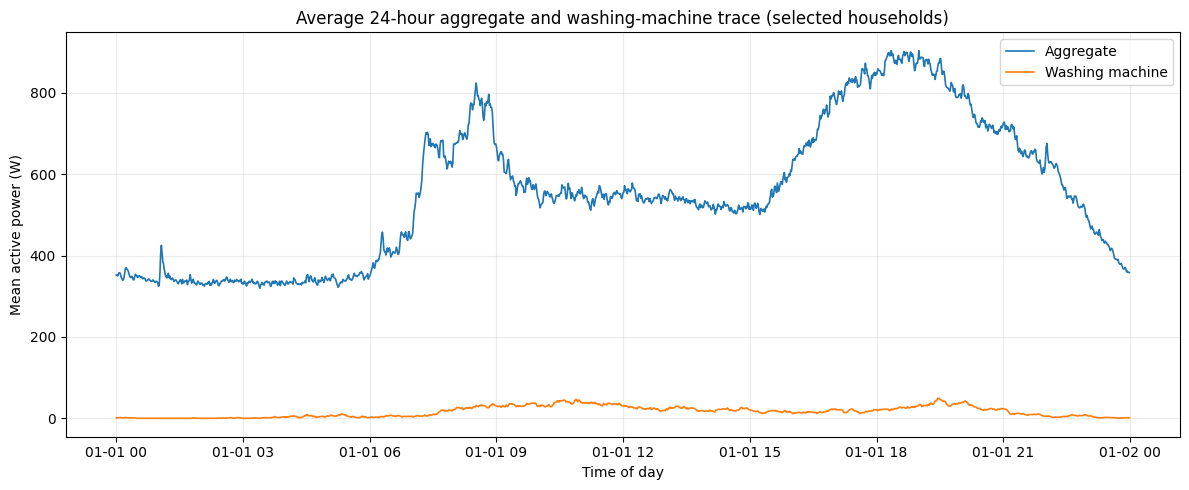

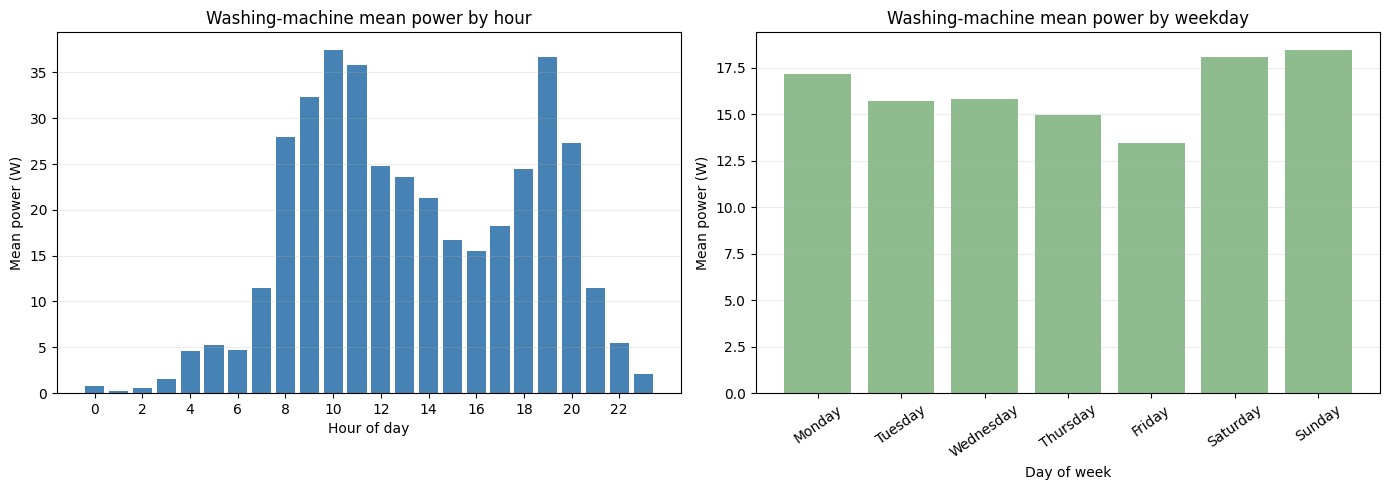

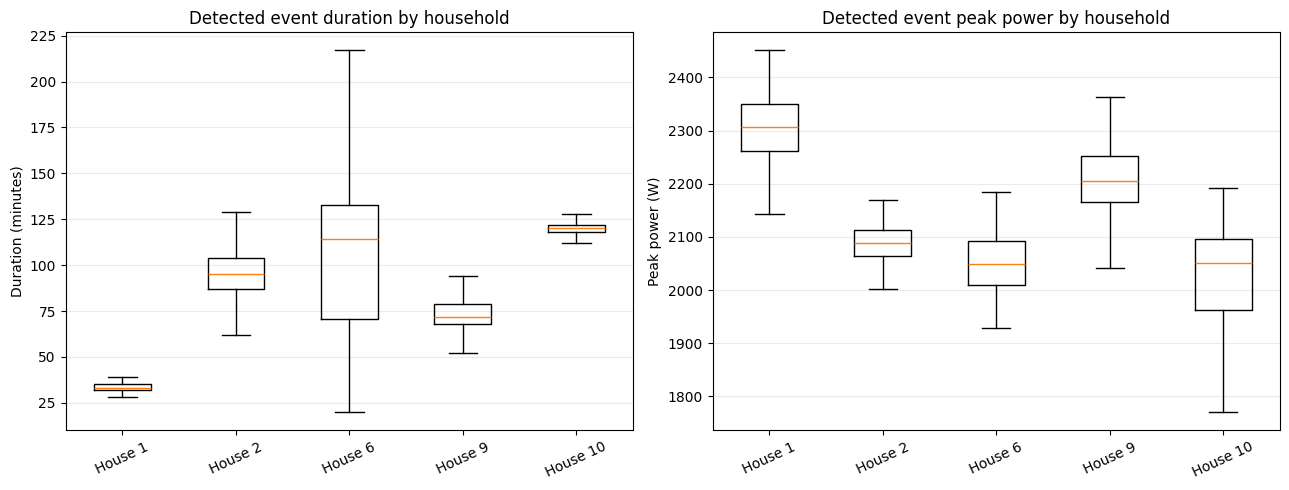

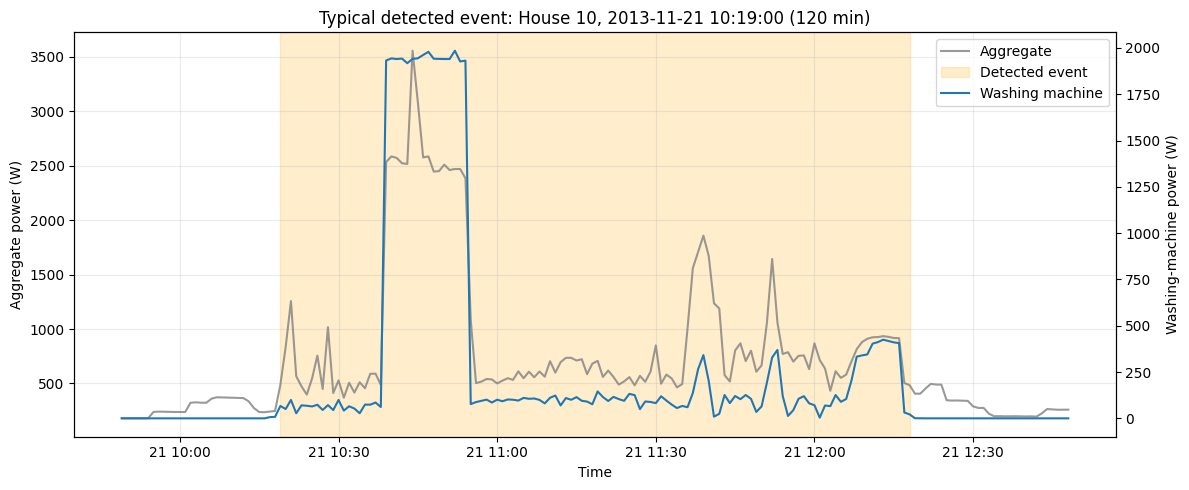

Saved EDA tables, plots, and report to outputs\02_washing_machine_eda
Typical event plot: House 10, 2013-11-21 10:19:00 to 2013-11-21 12:18:00; 120 minutes


In [3]:
fig, axis = plt.subplots(figsize=(12, 5))
clock = pd.to_datetime(daily_trace["time_of_day"], format="%H:%M")
axis.plot(clock, daily_trace["Aggregate"], label="Aggregate", linewidth=1.2)
axis.plot(clock, daily_trace["WashingMachine"], label="Washing machine", linewidth=1.2)
axis.set(title="Average 24-hour aggregate and washing-machine trace (selected households)",
         xlabel="Time of day", ylabel="Mean active power (W)")
axis.grid(alpha=0.25)
axis.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "average_24_hour_trace.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(hourly["hour"], hourly["mean_power_w"], color="steelblue")
axes[0].set(title="Washing-machine mean power by hour", xlabel="Hour of day", ylabel="Mean power (W)", xticks=range(0, 24, 2))
axes[0].grid(axis="y", alpha=0.25)
axes[1].bar(weekday["day"], weekday["mean_power_w"], color="darkseagreen")
axes[1].set(title="Washing-machine mean power by weekday", xlabel="Day of week", ylabel="Mean power (W)")
axes[1].tick_params(axis="x", rotation=35)
axes[1].grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "hour_and_weekday_usage.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
house_order = list(WASHING_MACHINE_CHANNELS)
duration_values = [events.loc[events["house"] == house, "duration_minutes"].to_numpy() for house in house_order]
peak_values = [events.loc[events["house"] == house, "peak_power_w"].to_numpy() for house in house_order]
labels = [f"House {house}" for house in house_order]
axes[0].boxplot(duration_values, labels=labels, showfliers=False)
axes[0].set(title="Detected event duration by household", ylabel="Duration (minutes)")
axes[1].boxplot(peak_values, labels=labels, showfliers=False)
axes[1].set(title="Detected event peak power by household", ylabel="Peak power (W)")
for axis in axes:
    axis.tick_params(axis="x", rotation=25)
    axis.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "cross_household_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

if events.empty:
    raise ValueError("No operating events met the stated threshold and duration rule.")
counts_by_house = events.groupby("house").size().reindex(house_order, fill_value=0)
example_house = int(counts_by_house.idxmax())
house_events = events.loc[events["house"] == example_house].copy()
typical_duration = house_events["duration_minutes"].median()
example = house_events.loc[(house_events["duration_minutes"] - typical_duration).abs().idxmin()]
example_start = example["start"]
example_end = example["end"]
example_window = profiles[example_house].loc[
    example_start - pd.Timedelta(minutes=30):example_end + pd.Timedelta(minutes=30)
]
fig, aggregate_axis = plt.subplots(figsize=(12, 5))
machine_axis = aggregate_axis.twinx()
aggregate_axis.plot(example_window.index, example_window["Aggregate"], color="gray", alpha=0.8, label="Aggregate")
machine_axis.plot(example_window.index, example_window["WashingMachine"], color="tab:blue", label="Washing machine")
aggregate_axis.axvspan(example_start, example_end, color="orange", alpha=0.2, label="Detected event")
aggregate_axis.set_ylabel("Aggregate power (W)")
machine_axis.set_ylabel("Washing-machine power (W)")
aggregate_axis.set_title(f"Typical detected event: House {example_house}, {example_start} ({int(example['duration_minutes'])} min)")
aggregate_axis.set_xlabel("Time")
aggregate_axis.grid(alpha=0.25)
lines_a, labels_a = aggregate_axis.get_legend_handles_labels()
lines_m, labels_m = machine_axis.get_legend_handles_labels()
aggregate_axis.legend(lines_a + lines_m, labels_a + labels_m, loc="upper right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "example_washing_machine_event.png", dpi=160, bbox_inches="tight")
plt.show()

hour_peak = int(hourly.loc[hourly["mean_power_w"].idxmax(), "hour"])
weekday_peak_power = weekday.loc[weekday["mean_power_w"].idxmax(), "day"]
weekday_peak_events = weekday.loc[weekday["events_starting"].idxmax(), "day"]
event_median_duration = float(events["duration_minutes"].median())
event_median_peak = float(events["peak_power_w"].median())
house_table = quality[["house", "washing_machine_channel", "date_start", "date_end", "interval_median_seconds", "interval_p95_seconds", "gaps_over_60_seconds", "raw_washing_machine_missing_rows", "issues_percent", "zero_percent_of_valid_minutes", "event_count", "median_event_duration_minutes", "median_event_peak_power_w"]]
house_table.to_csv(OUTPUT_DIR / "household_comparison.csv", index=False)

report = [
    "# Washing-machine EDA findings",
    "",
    "## Households and data quality",
    "",
    "Selected households: " + ", ".join(f"House {h} (Appliance{a})" for h, a in WASHING_MACHINE_CHANNELS.items()) + ". Appliance mappings come from the supplied dataset documentation; the files report active power in watts.",
    "",
    "The source data is recorded at approximately 6-8 second intervals. The table reports the observed median and 95th-percentile interval, date range, quality-flag share, zero time, and event estimates for each chosen home.",
    "",
    house_table.to_string(index=False),
    "",
    "The official cleaned dataset notes that missing values have been forward-filled, so the original missingness cannot be reconstructed fully from these files. We still count timestamp gaps over 60 seconds after sorting and resample to one-minute means. `Issues == 1` timestamps are excluded from household appliance traces and events; their share is reported above. Household coverage is not identical, and the sample is a small UK study rather than a representative population.",
    "",
    "## Event and usage rule",
    "",
    f"A one-minute reading of at least {ACTIVE_THRESHOLD_W} W is active. Valid off periods of at most {MAX_BRIDGED_OFF_MINUTES} consecutive minutes between active runs are joined. Events shorter than {MIN_EVENT_DURATION_MINUTES} minutes are discarded. The resulting {len(events):,} events have median duration {event_median_duration:.1f} minutes and median peak power {event_median_peak:.1f} W. Bridging helps join heating/drum phases, but estimated event boundaries and duration depend on these thresholds.",
    "",
    f"Zero/off time is reported as the percentage of valid one-minute washing-machine values equal to zero; below-threshold time (<{ACTIVE_THRESHOLD_W} W) is also in `household_summary.csv`. Hours with the highest household-averaged mean washing-machine power: {hour_peak:02d}:00. Weekday with the highest average washing-machine power: {weekday_peak_power}; weekday with the most detected event starts: {weekday_peak_events}.",
    "",
    "## Research context",
    "",
    "Murray et al. (2017) describe REFIT and its approximately 8-second readings. Khazaei et al. (2020) evaluate simple NILM methods and preprocessing on REFIT and REDD at one-minute resolution, motivating a manageable analysis and common interval. Batra et al. (2014) motivate reproducible evaluation. Our event thresholds are project heuristics, not thresholds claimed from these papers. Full citations: project-root `REFERENCES.md`.",
    "",
    "## Plot interpretations",
    "",
    "- `average_24_hour_trace.png`: shows the equal-household average aggregate and washing-machine traces at each minute of the day. The washer trace is much smaller than the aggregate, illustrating why identifying it from whole-house load alone is difficult.",
    f"- `hour_and_weekday_usage.png`: compares household-averaged power by hour and weekday; the highest hour in this sample is {hour_peak:02d}:00 and the weekday power peak is {weekday_peak_power}. These are descriptive patterns, not causal or population-wide estimates.",
    f"- `example_washing_machine_event.png`: overlays aggregate and washer power for a typical event in House {example_house}, with the detected interval shaded. Other household loads remain visible in the aggregate and can coincide with the washer.",
    "- `cross_household_comparison.png`: compares detected event-duration and peak-power distributions. Differences reflect both household behavior/appliances and the same threshold rule; the boxes are not a controlled comparison.",
    "",
    "## Output files",
    "",
    "Tables: `household_summary.csv`, `household_comparison.csv`, `detected_events.csv`, `usage_by_hour.csv`, `usage_by_weekday.csv`, `average_24_hour_trace.csv`. Plots: `average_24_hour_trace.png`, `hour_and_weekday_usage.png`, `cross_household_comparison.png`, `example_washing_machine_event.png`.",
]
(OUTPUT_DIR / "eda_findings.md").write_text("\n".join(report) + "\n", encoding="utf-8")
print(f"Saved EDA tables, plots, and report to {OUTPUT_DIR.relative_to(PROJECT_ROOT)}")
print(f"Typical event plot: House {example_house}, {example_start} to {example_end}; {int(example['duration_minutes'])} minutes")